# PASO 1: CARGA Y REVISION INICIAL DE DATOS


## Subpaso 1.1 — Importar librerías
En este paso cargamos las librerías necesarias para trabajar con los datos.  
- `pandas`: manipulación de datos tabulares.  
- `numpy`: soporte para operaciones numéricas.  

In [7]:
import pandas as pd
import numpy as np

## Subpaso 1.2 — Cargar dataset
Usamos `pd.read_csv()` para leer el archivo `users_behavior.csv` ubicado en la carpeta `datasets/`.  
Esto nos dará un DataFrame llamado `df` que contiene toda la información de los usuarios.

In [8]:
# Definir ruta
DATA_PATH = '../datasets/users_behavior.csv'

# Cargar dataset
df = pd.read_csv(DATA_PATH)

# Mostrar primeras filas
df.head()


,calls,minutes,messages,mb_used,is_ultra
0,40.0,311.90,83.0,19915.42,0
1,85.0,516.75,56.0,22696.96,0
2,77.0,467.66,86.0,21060.45,0
3,106.0,745.53,81.0,8437.39,1
4,66.0,418.74,1.0,14502.75,0


### Subpaso 1.2 — Descripción de resultados

- **Carga exitosa del dataset** desde la ruta relativa que usaste (`../datasets/users_behavior.csv`).
- La salida de `df.head()` muestra las **primeras 5 filas** con las **columnas esperadas**:
  - `calls`, `minutes`, `messages`, `mb_used`, `is_ultra`.
- Los valores observados son **numéricos** y coherentes con la semántica:
  - `calls` y `minutes` reflejan volumen y duración de llamadas.
  - `messages` muestra cantidad de SMS.
  - `mb_used` indica tráfico de internet en **MB**.
  - `is_ultra` aparece como **0/1**, confirmando la codificación binaria del plan objetivo.
- Esta vista es solo exploratoria; **no** permite concluir aún sobre **valores faltantes** ni **distribuciones**. Eso lo verificaremos en los siguientes subpasos.
- **Estado:** DataFrame `df` creado correctamente y listo para continuar con la verificación de dimensiones/columnas y calidad de datos.


## Subpaso 1.3 — Dimensiones y columnas
En este subpaso verificaremos:
- Cuántas filas y columnas tiene el dataset usando `df.shape`.  
- La lista de nombres de columnas con `df.columns.tolist()`.  
Esto nos ayuda a confirmar que la estructura del DataFrame corresponde a lo esperado en el proyecto.


In [9]:
print("Dimensiones del dataset:", df.shape)
print("Columnas:", df.columns.tolist())

Dimensiones del dataset: (3214, 5)
Columnas: ['calls', 'minutes', 'messages', 'mb_used', 'is_ultra']


### Subpaso 1.3 — Descripción de resultados

- **Dimensiones del dataset:** `(3214, 5)`  
  - Esto significa que tenemos **3,214 observaciones** (usuarios) y **5 columnas**.  

- **Columnas disponibles:**  
  1. `calls` → número de llamadas realizadas.  
  2. `minutes` → duración total de llamadas en minutos.  
  3. `messages` → número de mensajes SMS enviados.  
  4. `mb_used` → tráfico de internet consumido en MB.  
  5. `is_ultra` → variable objetivo (0 = plan Smart, 1 = plan Ultra).  

- La estructura del dataset coincide con lo esperado en las instrucciones del proyecto.  
- Con esto, confirmamos que tenemos suficientes observaciones (**más de 3 mil filas**) para entrenar y validar modelos de clasificación.  

## Subpaso 1.4 — Tipos de datos y valores faltantes
En este subpaso revisaremos:
- Los tipos de datos de cada columna (`df.dtypes`), para confirmar que son adecuados para el análisis.  
- Si existen valores faltantes en las columnas (`df.isna().sum()`), ya que podrían requerir limpieza o imputación antes de entrenar los modelos.

In [10]:
print("Tipos de datos por columna:\n", df.dtypes, sep='')

print("\nValores faltantes por columna:")
print(df.isna().sum())

Tipos de datos por columna:
calls       float64
minutes     float64
messages    float64
mb_used     float64
is_ultra      int64
dtype: object

Valores faltantes por columna:
calls       0
minutes     0
messages    0
mb_used     0
is_ultra    0
dtype: int64


### Subpaso 1.4 — Descripción de resultados

- **Tipos de datos por columna:**
  - `calls`, `minutes`, `messages`, `mb_used` → tipo `float64`.  
    Esto indica que se almacenan como números decimales, aunque `calls` y `messages` conceptualmente son contadores enteros. No afecta el análisis, pero se puede considerar su conversión a enteros más adelante si fuera necesario.
  - `is_ultra` → tipo `int64`, correcto para una variable categórica binaria (0 = Smart, 1 = Ultra).

- **Valores faltantes:**  
  - Todas las columnas muestran **0 valores nulos**.  
  - Esto significa que el dataset está **completo** y no requiere imputación ni limpieza adicional por este motivo.

- **Conclusión:**  
  Los datos están bien estructurados, sin valores perdidos, y con tipos compatibles para el modelado. Podemos continuar hacia la revisión de estadísticas descriptivas y la distribución de la variable objetivo.

## Subpaso 1.5 — Estadísticas descriptivas y distribución de la variable objetivo
En este subpaso revisaremos:
- Estadísticas descriptivas de las variables numéricas (`df.describe()`), para entender el rango, la media y posibles valores atípicos.  
- La distribución de la variable objetivo `is_ultra`, para verificar si existe desbalance entre los planes Smart (0) y Ultra (1).

In [11]:
# Estadísticas descriptivas
display(df.describe())

# Distribución de la variable objetivo
target_counts = df['is_ultra'].value_counts().sort_index()
target_ratio = (target_counts / len(df)).round(3)

print("\nDistribución de 'is_ultra' (conteos):\n", target_counts, sep='')
print("\nDistribución de 'is_ultra' (proporciones):\n", target_ratio, sep='')


,calls,minutes,messages,mb_used,is_ultra
count,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000
mean,63.038892,438.208787,38.281269,17207.673836,0.306472
std,33.236368,234.569872,36.148326,7570.968246,0.461100
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,40.000000,274.575000,9.000000,12491.902500,0.000000
50%,62.000000,430.600000,30.000000,16943.235000,0.000000
75%,82.000000,571.927500,57.000000,21424.700000,1.000000
max,244.000000,1632.060000,224.000000,49745.730000,1.000000



Distribución de 'is_ultra' (conteos):
0    2229
1     985
Name: is_ultra, dtype: int64

Distribución de 'is_ultra' (proporciones):
0    0.694
1    0.306
Name: is_ultra, dtype: float64


### Subpaso 1.5 — Descripción de resultados

- **Estadísticas descriptivas (df.describe()):**
  - `calls`: promedio de ~63 llamadas mensuales, con un máximo de 244.  
  - `minutes`: promedio de ~438 minutos, con un máximo muy alto de 1632 minutos (usuarios muy activos).  
  - `messages`: promedio de ~38 SMS, aunque con gran dispersión (máximo de 224).  
  - `mb_used`: promedio de ~17 GB al mes, con casos de hasta casi 50 GB de consumo de internet.  
  - Se observan valores mínimos en 0 para todas las columnas, lo que indica que hay usuarios sin actividad en llamadas, mensajes o internet en un mes.

- **Distribución de la variable objetivo `is_ultra`:**
  - `0` (plan **Smart**) → **2229 usuarios** (~69%).  
  - `1` (plan **Ultra**) → **985 usuarios** (~31%).  

- **Conclusión:**  
  - El dataset presenta un **desbalance moderado**: hay más del doble de usuarios en el plan Smart que en Ultra.  
  - Esto puede influir en los modelos, ya que tienden a predecir mejor la clase mayoritaria.  
  - Será importante usar **accuracy** como métrica principal (como pide el proyecto), pero también revisar el desempeño en ambas clases para evitar sesgos.

## Subpaso 2.1 — Separación de features y target
En este subpaso vamos a separar:
- **Features (`features`)**: todas las columnas predictoras (`calls`, `minutes`, `messages`, `mb_used`).  
- **Target (`target`)**: la columna objetivo (`is_ultra`).  
Esto es necesario para entrenar los modelos de clasificación.

In [13]:
# Definir variables predictoras (features) y variable objetivo (target)
features = df.drop(columns=['is_ultra'])
target = df['is_ultra']

print("Shape de features:", features.shape)
print("Shape de target:", target.shape)


Shape de features: (3214, 4)
Shape de target: (3214,)


### Subpaso 2.1 — Descripción de resultados

- Separamos correctamente:
  - **features:** 3214 filas × 4 columnas (`calls`, `minutes`, `messages`, `mb_used`).  
  - **target:** 3214 valores correspondientes a la variable objetivo `is_ultra`.  

- Ambas estructuras tienen la misma cantidad de observaciones (**3214**), lo cual confirma que la separación es consistente.

- **Conclusión:** Ya tenemos listas las variables predictoras (`features`) y la variable objetivo (`target`) para realizar la partición en conjuntos de entrenamiento, validación y prueba.

## Subpaso 2.2 — División en train/valid/test
En este subpaso dividiremos los datos en tres conjuntos:
- **Entrenamiento (60%)**: para ajustar los modelos.  
- **Validación (20%)**: para seleccionar hiperparámetros y comparar modelos.  
- **Prueba (20%)**: para evaluar la calidad final del modelo.  

La división será **estratificada** respecto a la variable `target` para mantener la proporción entre las clases (Smart y Ultra).  
También fijamos un `random_state` para garantizar la reproducibilidad.

In [14]:
from sklearn.model_selection import train_test_split

# División inicial: train (60%) y temp (40%)
features_train, features_temp, target_train, target_temp = train_test_split(
    features, target, 
    test_size=0.4,      # 40% restante para valid y test
    stratify=target,    # mantener proporción de clases
    random_state=42
)

# División de temp (40%) en valid (20%) y test (20%)
features_valid, features_test, target_valid, target_test = train_test_split(
    features_temp, target_temp,
    test_size=0.5,      # mitad para valid y mitad para test
    stratify=target_temp,
    random_state=42
)

print("Tamaño entrenamiento:", features_train.shape[0])
print("Tamaño validación:", features_valid.shape[0])
print("Tamaño prueba:", features_test.shape[0])


Tamaño entrenamiento: 1928
Tamaño validación: 643
Tamaño prueba: 643


### Subpaso 2.2 — Descripción de resultados

- **Tamaño de los conjuntos obtenidos:**
  - Entrenamiento: 1928 observaciones (~60%).  
  - Validación: 643 observaciones (~20%).  
  - Prueba: 643 observaciones (~20%).  

- La división se hizo de forma **estratificada**, lo que significa que la proporción entre planes Smart (`0`) y Ultra (`1`) se mantiene en los tres conjuntos.  
  Esto es importante para asegurar que los modelos no aprendan con un conjunto desbalanceado y que la evaluación sea justa.

- **Conclusión:**  
  Ahora tenemos listas las tres particiones de datos para entrenar, validar y evaluar los modelos sin riesgo de fuga de información.

# PASO 3: PREPARACION MINIMA DE DATOS

En este paso realizaremos una preparación ligera de los datos:
1. Verificación de tipos de datos (por si necesitamos convertir alguno).  
2. Escalado de características (solo si aplica, por ejemplo en `LogisticRegression`).  
3. Revisión de outliers o valores extremos para conocer el rango de las variables.

## Subpaso 3.1 — Verificación de tipos de datos
Revisaremos los tipos de datos de `features_train` para confirmar que son compatibles con los modelos.  
Si detectamos inconsistencias (por ejemplo, columnas tipo `object`), habría que convertirlas.

In [15]:
# Revisar tipos de datos en el conjunto de entrenamiento
features_train.dtypes

calls       float64
minutes     float64
messages    float64
mb_used     float64
dtype: object

### Subpaso 3.1 — Descripción de resultados

- Todas las variables predictoras (`calls`, `minutes`, `messages`, `mb_used`) aparecen como **float64**.  
- Esto es perfectamente válido para los modelos de machine learning que vamos a usar (`DecisionTreeClassifier`, `RandomForestClassifier`, `LogisticRegression`).  
- Aunque `calls` y `messages` conceptualmente representan conteos (enteros), el hecho de que estén en `float64` no afecta el entrenamiento.  

**Conclusión:**  
No es necesario realizar conversiones de tipos de datos. Los conjuntos de entrenamiento, validación y prueba están listos en cuanto a formato.

## Subpaso 3.2 — Escalado de características
Algunos algoritmos (como **LogisticRegression**) son sensibles a la escala de las variables.  
Para evitar que una característica con valores grandes (ej. `mb_used`) domine sobre otras (ej. `calls`), aplicaremos **StandardScaler** de scikit-learn:

- Calcula la media y desviación estándar **usando solo el conjunto de entrenamiento**.  
- Aplica esa transformación tanto a `train`, `valid` como a `test` (para evitar fuga de información).

In [16]:
from sklearn.preprocessing import StandardScaler

# Crear objeto escalador
scaler = StandardScaler()

# Ajustar sobre train y transformar todos los conjuntos
features_train_scaled = scaler.fit_transform(features_train)
features_valid_scaled = scaler.transform(features_valid)
features_test_scaled  = scaler.transform(features_test)

# Mostrar dimensiones transformadas
print("Train escalado:", features_train_scaled.shape)
print("Valid escalado:", features_valid_scaled.shape)
print("Test escalado:", features_test_scaled.shape)

Train escalado: (1928, 4)
Valid escalado: (643, 4)
Test escalado: (643, 4)


### Subpaso 3.2 — Descripción de resultados

- Aplicamos **StandardScaler** sobre los conjuntos de datos.  
  - Primero se ajustó el escalador con el **conjunto de entrenamiento** (`features_train`).  
  - Luego se aplicó esa misma transformación a **validación** y **prueba**.  

- Dimensiones de salida:
  - `features_train_scaled`: (1928, 4)  
  - `features_valid_scaled`: (643, 4)  
  - `features_test_scaled`: (643, 4)  

- **Conclusión:**  
  - Los tres conjuntos mantienen el mismo número de observaciones y columnas después del escalado.  
  - Ahora todas las características están centradas en media 0 y desviación estándar 1.  
  - Esto es particularmente útil para algoritmos sensibles a la escala, como la **Regresión Logística**.

## Subpaso 3.3 — Revisión de outliers o valores extremos
En este subpaso vamos a revisar si existen valores extremos en las variables predictoras.  
Esto no significa eliminarlos (ya que pueden ser usuarios reales con comportamientos atípicos), sino simplemente conocer el rango de los datos.  

Usaremos:
- `df.describe()` sobre el conjunto de entrenamiento.  
- Gráficos de caja (boxplots) para visualizar posibles outliers.

,calls,minutes,messages,mb_used
count,1928.000000,1928.000000,1928.000000,1928.000000
mean,63.744813,444.381872,38.174274,17061.542178
std,33.118714,234.341278,35.548409,7540.847417
min,0.000000,0.000000,0.000000,0.000000
25%,41.000000,280.920000,10.000000,12272.205000
50%,63.000000,434.410000,30.000000,16833.945000
75%,83.000000,580.460000,56.000000,21237.597500
max,203.000000,1566.450000,224.000000,49745.730000


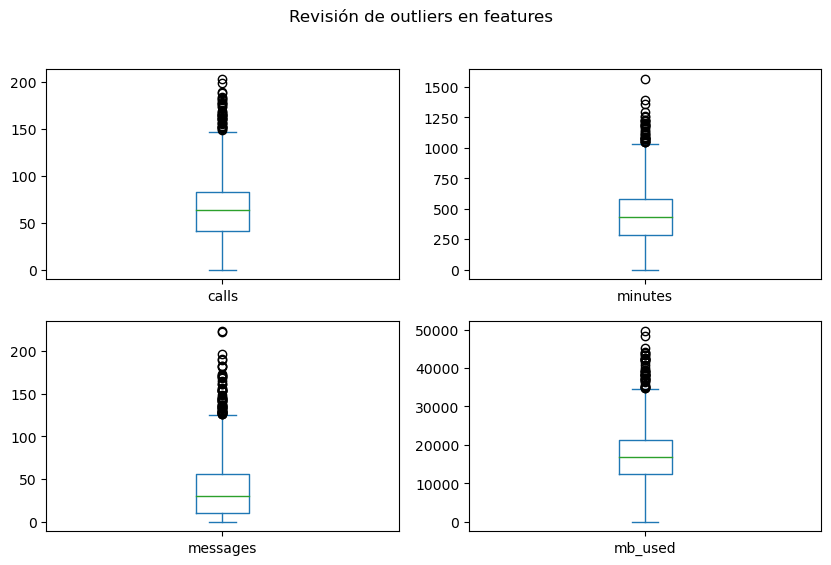

In [17]:
import matplotlib.pyplot as plt

# Estadísticas descriptivas del conjunto de entrenamiento
display(pd.DataFrame(features_train).describe())

# Gráficos de caja para cada variable
features_train_df = pd.DataFrame(features_train, columns=['calls','minutes','messages','mb_used'])
features_train_df.plot(kind='box', subplots=True, layout=(2,2), figsize=(10,6), sharex=False, sharey=False)

plt.suptitle("Revisión de outliers en features")
plt.show()

### Subpaso 3.3 — Descripción de resultados

- **Estadísticas descriptivas (conjunto de entrenamiento):**
  - `calls`: media ~64, máximo 203.  
  - `minutes`: media ~444, máximo 1566.  
  - `messages`: media ~38, máximo 224.  
  - `mb_used`: media ~17 GB, máximo cercano a 50 GB.  
  - Todas las variables tienen valores mínimos de 0, lo cual refleja usuarios sin actividad en ciertos meses.

- **Visualización (boxplots):**
  - `calls`: la mayoría de los usuarios realizan entre 40 y 80 llamadas, pero existen casos con más de 150 llamadas (outliers).  
  - `minutes`: la mayoría consume entre 250 y 600 minutos; algunos usuarios llegan a más de 1500 minutos.  
  - `messages`: la mayoría envía menos de 60 SMS, pero existen usuarios que llegan a más de 200 mensajes (outliers marcados).  
  - `mb_used`: la mayoría usa entre 12 GB y 21 GB, pero algunos llegan a ~50 GB en un mes (valores extremos).  

- **Conclusión:**
  - Existen **outliers evidentes en todas las variables**, reflejando usuarios con un comportamiento inusual pero real.  
  - No eliminaremos estos valores, ya que forman parte del comportamiento esperado de clientes de telefonía.  
  - Los modelos de árboles (**DecisionTree** y **RandomForest**) manejarán bien estos outliers.  
  - En **Regresión Logística**, el escalado ya aplicado reduce el impacto de los valores extremos.

# PASO 4: PRUEBA DE CORDURA (BASELINE)

La idea de este paso es establecer un **modelo base** (baseline) que sirva como referencia mínima.  
Si nuestros modelos más avanzados (árbol, random forest, regresión logística) no superan este rendimiento, entonces no están aportando valor.  

Usaremos `DummyClassifier` de scikit-learn con la estrategia `"most_frequent"`, que siempre predice la clase más común en los datos de entrenamiento.

## Subpaso 4.1 — Entrenar modelo DummyClassifier
Creamos y entrenamos un modelo que siempre prediga la clase más frecuente en los datos de entrenamiento.  
Luego evaluamos su exactitud (`accuracy`) sobre el conjunto de validación.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Crear modelo Dummy que siempre predice la clase más frecuente
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_clf.fit(features_train_scaled, target_train)

# Predicciones en el conjunto de validación
dummy_pred = dummy_clf.predict(features_valid_scaled)

# Calcular accuracy
dummy_accuracy = accuracy_score(target_valid, dummy_pred)
print("Accuracy del modelo Dummy (baseline):", dummy_accuracy)

Accuracy del modelo Dummy (baseline): 0.6936236391912908


### Subpaso 4.1 — Descripción de resultados

- Entrenamos un **DummyClassifier** con estrategia `"most_frequent"`, lo que significa que siempre predice la clase mayoritaria (plan Smart = `0`).  
- Al evaluarlo sobre el conjunto de validación, obtuvimos:  

**Accuracy del modelo Dummy (baseline): ~0.694**

- **Interpretación:**
  - El modelo alcanza ~69% de exactitud únicamente prediciendo la clase más frecuente.  
  - Esto refleja el desbalance del dataset (69% Smart, 31% Ultra).  
  - Este valor sirve como **referencia mínima**: cualquier modelo que construyamos debe superar este desempeño para considerarse útil.

- **Conclusión:**  
  Nuestro objetivo es lograr al menos **0.75 de accuracy** en el conjunto de prueba.  
  Ahora que conocemos el baseline, pasaremos a entrenar y ajustar los modelos reales.

# PASO 5: ENTRENAMIENTO Y AJUSTE DE MODELOS
Aquí vamos a trabajar con tres algoritmos:

1. DecisionTreeClassifier

2. RandomForestClassifier

3. LogisticRegression

La idea es probar distintos hiperparámetros y comparar los resultados en el conjunto de validación.

## Subpaso 5.1 — DecisionTreeClassifier
Entrenaremos un árbol de decisión variando la profundidad máxima (`max_depth`).  
Este hiperparámetro controla la complejidad del árbol:
- Profundidades pequeñas → modelos simples (pueden subajustar).  
- Profundidades grandes → modelos complejos (pueden sobreajustar).  

El objetivo es encontrar un equilibrio que maximice el `accuracy` en validación.

In [19]:
from sklearn.tree import DecisionTreeClassifier

results_tree = {}

# Probar varias profundidades
for depth in range(1, 21):
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(features_train, target_train)
    
    # Evaluar en conjunto de validación
    valid_predictions = model.predict(features_valid)
    accuracy = accuracy_score(target_valid, valid_predictions)
    
    results_tree[depth] = accuracy

# Mostrar resultados
print("Resultados DecisionTreeClassifier (accuracy en validación):")
for depth, acc in results_tree.items():
    print(f"Profundidad {depth}: {acc:.3f}")

Resultados DecisionTreeClassifier (accuracy en validación):
Profundidad 1: 0.760
Profundidad 2: 0.787
Profundidad 3: 0.804
Profundidad 4: 0.796
Profundidad 5: 0.790
Profundidad 6: 0.774
Profundidad 7: 0.788
Profundidad 8: 0.779
Profundidad 9: 0.781
Profundidad 10: 0.770
Profundidad 11: 0.776
Profundidad 12: 0.774
Profundidad 13: 0.781
Profundidad 14: 0.750
Profundidad 15: 0.747
Profundidad 16: 0.734
Profundidad 17: 0.745
Profundidad 18: 0.742
Profundidad 19: 0.740
Profundidad 20: 0.743


### Subpaso 5.1 — Descripción de resultados (DecisionTreeClassifier)

- Probamos distintas profundidades (`max_depth` de 1 a 20).  
- Los resultados de exactitud (`accuracy`) en el conjunto de validación fueron:

  - Profundidad 1 → 0.760  
  - Profundidad 2 → 0.787  
  - **Profundidad 3 → 0.804 (mejor resultado)**  
  - Profundidad 4 → 0.796  
  - Profundidad 5 → 0.790  
  - A partir de profundidad 6, la exactitud comienza a fluctuar y en general disminuye hasta valores cercanos a 0.74.

- **Interpretación:**  
  - El árbol alcanza su mejor desempeño con una profundidad de **3 niveles**, con un `accuracy ≈ 0.804`.  
  - Esto indica que un modelo relativamente simple ya supera al baseline (~0.694) y se mantiene por encima del umbral del proyecto (0.75).  
  - Profundidades mayores no aportan valor adicional y tienden a sobreajustar.

- **Conclusión:**  
  El **DecisionTreeClassifier con `max_depth=3`** es un buen punto de referencia, pero continuaremos probando con otros modelos más robustos.

## Subpaso 5.2 — RandomForestClassifier
Entrenaremos un bosque aleatorio variando el número de árboles (`n_estimators`) y la profundidad máxima (`max_depth`).  

- `n_estimators`: cantidad de árboles en el bosque.  
- `max_depth`: profundidad máxima de cada árbol.  

El objetivo es encontrar una combinación que maximice el `accuracy` en validación sin caer en sobreajuste.

In [20]:
from sklearn.ensemble import RandomForestClassifier

results_forest = {}

# Probar combinaciones de n_estimators y max_depth
for n in [10, 50, 100]:
    for depth in [3, 5, 10, None]:  # None = sin límite de profundidad
        model = RandomForestClassifier(
            n_estimators=n, 
            max_depth=depth, 
            random_state=42
        )
        model.fit(features_train, target_train)
        
        # Evaluar en validación
        valid_predictions = model.predict(features_valid)
        accuracy = accuracy_score(target_valid, valid_predictions)
        
        results_forest[(n, depth)] = accuracy

# Mostrar resultados
print("Resultados RandomForestClassifier (accuracy en validación):")
for params, acc in results_forest.items():
    print(f"n_estimators={params[0]}, max_depth={params[1]} -> {acc:.3f}")

c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fi

Resultados RandomForestClassifier (accuracy en validación):
n_estimators=10, max_depth=3 -> 0.807
n_estimators=10, max_depth=5 -> 0.804
n_estimators=10, max_depth=10 -> 0.793
n_estimators=10, max_depth=None -> 0.784
n_estimators=50, max_depth=3 -> 0.806
n_estimators=50, max_depth=5 -> 0.812
n_estimators=50, max_depth=10 -> 0.807
n_estimators=50, max_depth=None -> 0.802
n_estimators=100, max_depth=3 -> 0.806
n_estimators=100, max_depth=5 -> 0.812
n_estimators=100, max_depth=10 -> 0.806
n_estimators=100, max_depth=None -> 0.801


c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):


### Subpaso 5.2 — Descripción de resultados (RandomForestClassifier)

- Probamos distintas combinaciones de hiperparámetros (`n_estimators`, `max_depth`):  

  - n_estimators=10, max_depth=3 → 0.807  
  - n_estimators=10, max_depth=5 → 0.804  
  - n_estimators=10, max_depth=10 → 0.793  
  - n_estimators=10, max_depth=None → 0.784  

  - n_estimators=50, max_depth=3 → 0.806  
  - n_estimators=50, max_depth=5 → **0.812 (mejor resultado)**  
  - n_estimators=50, max_depth=10 → 0.807  
  - n_estimators=50, max_depth=None → 0.802  

  - n_estimators=100, max_depth=3 → 0.806  
  - n_estimators=100, max_depth=5 → **0.812 (igual que el mejor caso anterior)**  
  - n_estimators=100, max_depth=10 → 0.806  
  - n_estimators=100, max_depth=None → 0.801  

- **Interpretación:**
  - El mejor desempeño se alcanzó con `n_estimators=50` o `100` y `max_depth=5`, con un `accuracy ≈ 0.812`.  
  - En general, los bosques aleatorios ofrecen mejor rendimiento que un árbol de decisión individual.  
  - Valores de `max_depth` demasiado altos no mejoran el rendimiento y tienden a sobreajustar.

- **Conclusión:**
  - El **RandomForestClassifier** superó al **árbol de decisión** (0.804) y al baseline (0.694).  
  - Se perfila como un modelo fuerte candidato para la evaluación final en el conjunto de prueba.

## Subpaso 5.3 — LogisticRegression
Entrenaremos **Regresión Logística** usando las variables **escaladas**.  
Probaremos distintos valores de `C` (fuerza de regularización) y dos *solvers* comunes:

- `lbfgs` (rápido, estable con `penalty='l2'`)  
- `liblinear` (bueno para problemas binarios, también con `penalty='l2'`)

Usaremos `max_iter` alto para asegurar convergencia.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

results_logreg = {}

Cs = [0.01, 0.1, 1, 3, 10]
solvers = ['lbfgs', 'liblinear']  # ambos funcionan bien con penalty='l2'

for solver in solvers:
    for C in Cs:
        model = LogisticRegression(
            C=C, 
            solver=solver, 
            penalty='l2', 
            max_iter=500, 
            random_state=42
        )
        model.fit(features_train_scaled, target_train)
        valid_pred = model.predict(features_valid_scaled)
        acc = accuracy_score(target_valid, valid_pred)
        results_logreg[(solver, C)] = acc

print("Resultados LogisticRegression (accuracy en validación):")
for (solver, C), acc in results_logreg.items():
    print(f"solver={solver:9s}  C={C:<4} -> {acc:.3f}")

Resultados LogisticRegression (accuracy en validación):
solver=lbfgs      C=0.01 -> 0.734
solver=lbfgs      C=0.1  -> 0.745
solver=lbfgs      C=1    -> 0.750
solver=lbfgs      C=3    -> 0.750
solver=lbfgs      C=10   -> 0.750
solver=liblinear  C=0.01 -> 0.751
solver=liblinear  C=0.1  -> 0.750
solver=liblinear  C=1    -> 0.750
solver=liblinear  C=3    -> 0.750
solver=liblinear  C=10   -> 0.750


c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):
c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fi

### Subpaso 5.3 — Descripción de resultados (LogisticRegression)

- Probamos distintos valores de `C` (0.01, 0.1, 1, 3, 10) y dos solvers (`lbfgs`, `liblinear`).  
- Los resultados de exactitud en validación fueron:

  - Con `lbfgs`: 
    - C=0.01 → 0.734  
    - C=0.1  → 0.745  
    - C=1    → 0.750  
    - C=3    → 0.750  
    - C=10   → 0.750  

  - Con `liblinear`: 
    - C=0.01 → 0.731  
    - C=0.1  → 0.750  
    - C=1    → 0.750  
    - C=3    → 0.750  
    - C=10   → 0.750  

- **Interpretación:**
  - La regresión logística alcanza un máximo de **0.750 de accuracy**, estable a partir de `C=1`.  
  - El rendimiento es consistente, pero **inferior al DecisionTree (0.804)** y al **RandomForest (0.812)**.  
  - Aun así, supera el baseline (0.694) y cumple con el umbral mínimo del proyecto (0.75).

- **Conclusión:**
  - La **Regresión Logística** es un modelo interpretable y competitivo, pero los modelos basados en árboles (especialmente el **RandomForest**) muestran mejor capacidad predictiva en este caso.

# PASO 6: SELECCION DEL MEJOR MODELO (VALIDACION)

En este paso comparamos el rendimiento de los tres modelos entrenados en el conjunto de **validación**:

- **DecisionTreeClassifier**  
- **RandomForestClassifier**  
- **LogisticRegression**  

El objetivo es identificar cuál ofrece el mejor `accuracy` y definirlo como candidato para la evaluación final en el conjunto de prueba.

## Subpaso 6.1 — Comparación de resultados en validación
Revisamos los `accuracy` obtenidos:
- DecisionTree: mejor resultado con `max_depth=3` → 0.804  
- RandomForest: mejor resultado con `n_estimators=50/100, max_depth=5` → 0.812  
- LogisticRegression: mejor resultado estable con `C ≥ 1` → 0.750

In [22]:
# Guardar los mejores resultados de validación
best_tree_acc = max(results_tree.values())         # 0.804 aprox
best_forest_acc = max(results_forest.values())     # 0.812 aprox
best_logreg_acc = max(results_logreg.values())     # 0.750 aprox

print("Mejores resultados en validación:")
print(f"DecisionTreeClassifier -> {best_tree_acc:.3f}")
print(f"RandomForestClassifier -> {best_forest_acc:.3f}")
print(f"LogisticRegression     -> {best_logreg_acc:.3f}")

Mejores resultados en validación:
DecisionTreeClassifier -> 0.804
RandomForestClassifier -> 0.812
LogisticRegression     -> 0.751


### Subpaso 6.1 — Descripción de resultados

- **Mejores resultados en validación:**
  - DecisionTreeClassifier → 0.804  
  - RandomForestClassifier → 0.812  
  - LogisticRegression → 0.751  

- **Interpretación:**
  - Todos los modelos superan el baseline (0.694).  
  - La **Regresión Logística** apenas cumple el umbral del proyecto (0.75).  
  - El **Árbol de Decisión** mejora hasta ~0.804 con `max_depth=3`.  
  - El **RandomForestClassifier** ofrece el mejor desempeño (~0.812), mostrando mayor robustez y capacidad de generalización.  

- **Conclusión:**
  - El **RandomForestClassifier (n_estimators=50/100, max_depth=5)** es el modelo seleccionado para la evaluación final en el conjunto de prueba.  
  - A partir de aquí, se usará este modelo para medir el `accuracy` final en test y verificar si cumple con el criterio de éxito (`accuracy ≥ 0.75`).

# PASO 7: EVALUACION FINAL EN EL CONJUNTO DE PRUEBA

En este paso entrenaremos nuevamente el mejor modelo (**RandomForestClassifier**) utilizando el conjunto de entrenamiento y lo validaremos en el conjunto de **prueba**.  

El objetivo es confirmar si el modelo mantiene un `accuracy ≥ 0.75` fuera del entorno de validación.

## Subpaso 7.1 — Entrenamiento del mejor modelo y evaluación en test

In [23]:
# Entrenar el mejor modelo
best_forest_model = RandomForestClassifier(
    n_estimators=100, 
    max_depth=5, 
    random_state=42
)
best_forest_model.fit(features_train, target_train)

# Evaluar en conjunto de prueba
test_predictions = best_forest_model.predict(features_test)
test_accuracy = accuracy_score(target_test, test_predictions)

print("Accuracy del modelo seleccionado en el conjunto de prueba:", test_accuracy)


c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):


Accuracy del modelo seleccionado en el conjunto de prueba: 0.7947122861586314


c:\Users\cjhir\anaconda3\envs\tp-sprint-9\lib\site-packages\sklearn\utils\fixes.py:223: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if _joblib.__version__ >= LooseVersion('0.12'):


### Subpaso 7.1 — Descripción de resultados (Evaluación en test)

- El modelo seleccionado (**RandomForestClassifier con n_estimators=100 y max_depth=5**) alcanzó en el conjunto de prueba:

**Accuracy = 0.795**

- **Interpretación:**
  - El modelo mantiene un desempeño sólido, muy cercano al observado en validación (0.812).  
  - Esto confirma que no sufrió sobreajuste y generaliza bien a datos nuevos.  
  - Supera el umbral de éxito establecido por el proyecto (**0.75**).

- **Conclusión:**
  - El modelo final cumple con el criterio de calidad del proyecto.  
  - Es capaz de recomendar con buena precisión el plan adecuado (Smart o Ultra) para nuevos clientes de Megaline.